In [3]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [7]:
#--- path of the dataset
DATASET_PATH = Path("../data/raw/beealarmed")

JSON_PATH = DATASET_PATH / "data.json"
IMAGE_PATH = DATASET_PATH / "images_300"

print("Dataset:", DATASET_PATH.resolve())
print("JSON:", JSON_PATH.resolve())
print("Images:", IMAGE_PATH.resolve())

with open(JSON_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)
print("Records:",len(data))

Dataset: D:\Documentos\ING. SISTEMAS\Semestre 6\DSD_SmartHive\pests_threats\data\raw\beealarmed
JSON: D:\Documentos\ING. SISTEMAS\Semestre 6\DSD_SmartHive\pests_threats\data\raw\beealarmed\data.json
Images: D:\Documentos\ING. SISTEMAS\Semestre 6\DSD_SmartHive\pests_threats\data\raw\beealarmed\images_300
Records: 7490


In [ ]:
#--- exploring json structure
first_key = next(iter(data))
print("first image:",first_key)
print("labels:")
print(data[first_key])

first image: iskZwzri42zg0vdZGVRJYIP25svQgQLc.jpeg
labels:
{'cooling': False, 'pollen': False, 'varroa': False, 'wasps': True}


In [15]:
records = []
for filename,labels in data.items():
    records.append({
        "filename": filename,
        "cooling": labels.get("cooling",False),
        "pollen": labels.get("pollen",False),
        "varroa": labels.get("varroa",False),
        "wasps": labels.get("wasps",False)
    })

df = pd.DataFrame(records)
df.head()

print("Total:",len(df))
print("Varroa images:", df["varroa"].sum())
print("Wasps images:", df["wasps"].sum())
print(
    "Varroa and Wasps:",
    ((df["varroa"]) & (df["wasps"])).sum()
)


Total: 7490
Varroa images: 1266
Wasps images: 950
Varroa and Wasps: 0


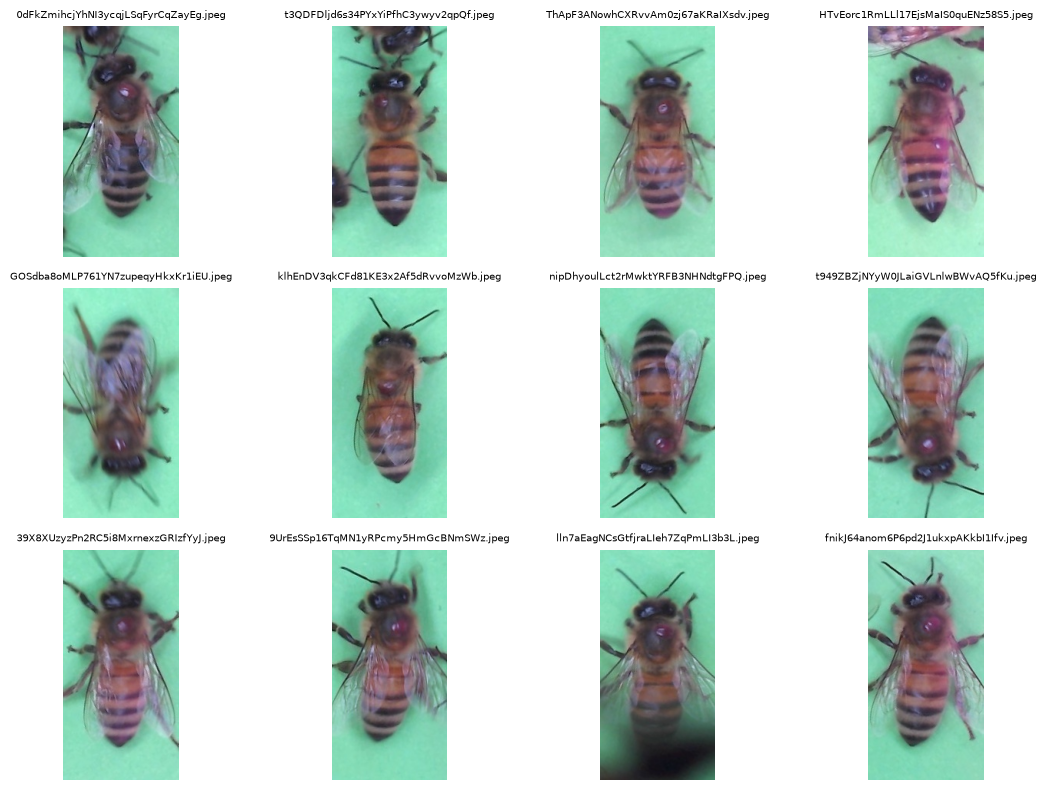

In [20]:
varroa_df = df[df["varroa"] == True].copy() #--- subset with the 1266 images labelled as varroa=1. 

IMAGE_PATH = DATASET_PATH / "images_300"
sample = varroa_df.sample(n=min(12,len(varroa_df)),random_state=98)

fig, axes = plt.subplots(3, 4, figsize=(12, 8))

for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    image_path = IMAGE_PATH / row["filename"]
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(row["filename"], fontsize=7)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:
VARROA_OUTPUT = DATASET_PATH.parent.parent / "selected" / "beealarmed" / "varroa"
VARROA_OUTPUT.mkdir(parents=True, exist_ok=True)
print(VARROA_OUTPUT.resolve())

D:\Documentos\ING. SISTEMAS\Semestre 6\DSD_SmartHive\pests_threats\data\selected\beealarmed\varroa


In [23]:
#--- copying the varroa images for visual inspection and annotation with bounding boxes.
IMAGE_PATH = DATASET_PATH / "images_300"
copied = 0
missing = []

import shutil
for filename in varroa_df["filename"]:
    source = IMAGE_PATH / filename
    destination = VARROA_OUTPUT / filename
    if source.exists():
        shutil.copy2(source, destination)
        copied += 1
    else:
        missing.append(filename)

print("Copied images:",copied)
print("Missing images:",len(missing))

Copied images: 1266
Missing images: 0


In [24]:
#--- same approach now with images labelled as wasp=1.
WASPS_OUTPUT = DATASET_PATH.parent.parent / "selected" / "beealarmed" / "wasps"
WASPS_OUTPUT.mkdir(parents=True, exist_ok=True)
print(WASPS_OUTPUT.resolve()) 

D:\Documentos\ING. SISTEMAS\Semestre 6\DSD_SmartHive\pests_threats\data\selected\beealarmed\wasps


In [25]:
IMAGE_PATH = DATASET_PATH / "images_300"
wasps_df = df[df["wasps"] == True].copy()
copied = 0
missing = []

for filename in wasps_df["filename"]:
    source = IMAGE_PATH / filename
    destination = WASPS_OUTPUT / filename
    if source.exists():
        shutil.copy2(source, destination)
        copied += 1
    else:
        missing.append(filename)

print("Copied images:",copied)
print("Missing images:",len(missing))

Copied images: 950
Missing images: 0
